<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">NHL Opening &amp; Closing Odds, US Books — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 8,301 NHL games from 1 August 2020 to 31 October 2026, opening and closing prices from FanDuel, DraftKings,
BetMGM, Caesars, BetRivers, BetOnline, theScore, Fanatics, Hard Rock, Pinnacle, Bet365, Kalshi and Polymarket, in American
odds, each with the time it was recorded.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written in plain sight in
the `CLAIMS` cell and next to the checks of the listing's images; everything else is read from the data. Only what the
file cannot show is not recomputed: the counts of prices left out while it was built (169 closing prices too far from
the market, 76 puck lines on the underdog, 14 openings far from the market, 20 markets taken from a second source).

🏒 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/gkqmny?utm_source=github&utm_medium=notebook&utm_campaign=nhl_us&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/nhl-opening-closing-odds-9-us-books-pinnacle-2020-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nhl_us&utm_content=whop_top) · free 20-game sample: same layout, same 288 columns.

In [1]:
import os, glob, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
NAME = "NHL_Opening_Closing_Odds_2020-2026"

def find_csv():
    """The CSV of the full product (the largest match wins: sample and full may both be attached), or the CSV inside the ZIP."""
    hits = []
    for base in (os.environ.get("NHL_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.csv"), recursive=True) if os.path.isfile(p)]
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.zip"), recursive=True) if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError(NAME + ".csv not found: attach the full dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
if PATH.endswith(".zip"):
    data = zipfile.ZipFile(PATH).read(NAME + ".csv")
    RAW = pd.read_csv(io.BytesIO(data), dtype=str, keep_default_na=False)
    F = pd.read_csv(io.BytesIO(data), low_memory=False)
else:
    RAW = pd.read_csv(PATH, dtype=str, keep_default_na=False)      # every cell exactly as written in the file
    F = pd.read_csv(PATH, low_memory=False)                          # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

RESULTS = []
def check(label, ok, detail=""):
    RESULTS.append((label, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + label + (f"   [{detail}]" if detail != "" else ""))

SOURCES = ["Pinnacle", "Bet365", "FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline", "theScore",
           "Fanatics", "HardRock", "Kalshi", "Polymarket"]
BOOKS = SOURCES[:11]
US_BOOKS = ["FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline", "theScore", "Fanatics", "HardRock"]
START = pd.to_datetime(RAW["Kickoff_UTC"])
def has(col): return RAW[col] != ""
def mins(col): return (pd.to_datetime(RAW[col].where(has(col))) - START).dt.total_seconds() / 60
def first_day(mask): return RAW.loc[mask, "Game_ID"].str[:8].min()

NHL_Opening_Closing_Odds_2020-2026.csv  ·  8,301 rows  ·  288 columns


## The claims
The expected values, copied from the README in the ZIP and from the listing.

In [2]:
CLAIMS = {
    # README and listing: the file
    "games": 8301, "seasons": 8, "columns": 288, "prices": 810920,
    "first_day": "20200801", "last_day": "20261031", "games_2026_27": 226, "playoff_games_2019_20": 130,
    "stages": {"Regular Season": 7654, "Playoffs": 647},
    "endings": {"Regulation": 6444, "Overtime": 1299, "Shootout": 558},
    # listing: first closing / opening moneyline, source by source (US Eastern dates)
    "first_close_ml": {"Pinnacle": "20200801", "Bet365": "20200801", "FanDuel": "20200801", "DraftKings": "20200801",
                       "Caesars": "20200801", "BetMGM": "20200803", "BetOnline": "20200804", "BetRivers": "20210517",
                       "theScore": "20231114", "HardRock": "20250314", "Fanatics": "20251007", "Kalshi": "20251217",
                       "Polymarket": "20260105"},
    "first_open_ml_late": {"BetRivers": "20211230", "HardRock": "20260929", "Fanatics": "20261003", "Kalshi": "20261021",
                           "Polymarket": "20261021"},
    # README "Said plainly" and listing "Read this before you buy"
    "arizona_games": 311, "arizona_bet365_ml": 302, "arizona_bet365_puckline": 309, "arizona_us_total": 306,
    "no_pinnacle_ml": 462, "no_pinnacle_ml_split": {"Arizona": 311, "Utah HC 2024-25": 82, "2020 playoffs": 58, "others": 11},
    "bet365_ml_close_median_min": -76, "pinnacle_ml_close_median_min": 5, "us_books_ml_close_median_min": -9,
    "fanatics_games_2025_26": 11, "kalshi_polymarket_same_close": (125, 219),
    "team_totals_period": ("20210113", "20260614"), "open_without_close": 3162,
    "min_close_ml_share_2026_27": 96,
}

## 1. The file
Games, seasons, stages, endings, columns and prices.

In [3]:
check("games", len(RAW) == CLAIMS["games"], len(RAW))
check("columns", RAW.shape[1] == CLAIMS["columns"], RAW.shape[1])
check("seasons", RAW["Season"].nunique() == CLAIMS["seasons"], RAW["Season"].nunique())
check("one row per game", RAW["Game_ID"].is_unique and RAW["NHL_Game_ID"].is_unique)
day = RAW["Game_ID"].str[:8]
check("first and last day (US Eastern)", (day.min(), day.max()) == (CLAIMS["first_day"], CLAIMS["last_day"]), (day.min(), day.max()))
check("2026-27 games", (RAW["Season"] == "2026/2027").sum() == CLAIMS["games_2026_27"])
check("2020 playoff games (2019-20)", ((RAW["Season"] == "2019/2020") & (RAW["Stage"] == "Playoffs")).sum() == CLAIMS["playoff_games_2019_20"]
      and (RAW["Season"] == "2019/2020").sum() == CLAIMS["playoff_games_2019_20"])
check("stages", RAW["Stage"].value_counts().to_dict() == CLAIMS["stages"], RAW["Stage"].value_counts().to_dict())
check("endings", RAW["Match_Ending"].value_counts().to_dict() == CLAIMS["endings"], RAW["Match_Ending"].value_counts().to_dict())
price_cols = [c for c in RAW.columns if c.split("_")[0] in SOURCES and not c.endswith("_Time") and "_Line_" not in c]
n_prices = int((RAW[price_cols] != "").sum().sum())
check("prices", n_prices == CLAIMS["prices"], f"{n_prices:,}")
per_source = {s: sum(c.startswith(s + "_") for c in RAW.columns) for s in SOURCES}
check("22 columns per book, 38 for Pinnacle, 6 for Kalshi and Polymarket",
      per_source == {**{s: 22 for s in BOOKS}, "Pinnacle": 38, "Kalshi": 6, "Polymarket": 6}, per_source)

PASS  games   [8301]
PASS  columns   [288]
PASS  seasons   [8]
PASS  one row per game
PASS  first and last day (US Eastern)   [('20200801', '20261031')]
PASS  2026-27 games
PASS  2020 playoff games (2019-20)
PASS  stages   [{'Regular Season': 7654, 'Playoffs': 647}]
PASS  endings   [{'Regulation': 6444, 'Overtime': 1299, 'Shootout': 558}]
PASS  prices   [810,920]
PASS  22 columns per book, 38 for Pinnacle, 6 for Kalshi and Polymarket   [{'Pinnacle': 38, 'Bet365': 22, 'FanDuel': 22, 'DraftKings': 22, 'BetMGM': 22, 'Caesars': 22, 'BetRivers': 22, 'BetOnline': 22, 'theScore': 22, 'Fanatics': 22, 'HardRock': 22, 'Kalshi': 6, 'Polymarket': 6}]


## 2. Scores
Final score, score after 60 minutes, how the game ended.

In [4]:
hs, aw = F["Home_Score"], F["Away_Score"]
check("Total_Score = home + away", (F["Total_Score"] == hs + aw).all())
check("Margin = |home - away|", (F["Margin"] == (hs - aw).abs()).all())
check("Winner follows the score", ((F["Winner"] == "Home") == (hs > aw)).all() and (hs != aw).all())
tied60 = F["Home_Score_60"] == F["Away_Score_60"]
check("Result_60 follows the score after 60 minutes", ((F["Result_60"] == "Draw") == tied60).all())
check("overtime and shootout games were tied after 60 minutes, regulation games were not",
      (tied60 == (F["Match_Ending"] != "Regulation")).all())
check("the loser's final score is its score after 60 minutes when the game went past 60",
      (np.minimum(hs, aw)[tied60] == F.loc[tied60, "Home_Score_60"]).all())
check("a shootout counts as one goal for the winner", ((hs - aw).abs()[F["Match_Ending"] == "Shootout"] == 1).all())

PASS  Total_Score = home + away
PASS  Margin = |home - away|
PASS  Winner follows the score
PASS  Result_60 follows the score after 60 minutes
PASS  overtime and shootout games were tied after 60 minutes, regulation games were not
PASS  the loser's final score is its score after 60 minutes when the game went past 60
PASS  a shootout counts as one goal for the winner


## 3. Each source, from when
The first closing and opening moneyline of each source, as the listing states them.

In [5]:
for s, d in CLAIMS["first_close_ml"].items():
    got = first_day(has(f"{s}_ML_Home_Close"))
    check(f"{s}: first closing moneyline {d}", got == d, got)
for s, d in CLAIMS["first_open_ml_late"].items():
    got = first_day(has(f"{s}_ML_Home_Open"))
    check(f"{s}: first opening moneyline {d}", got == d, got)
others = [s for s in SOURCES if s not in CLAIMS["first_open_ml_late"]]
gap = {s: (pd.Timestamp(first_day(has(f"{s}_ML_Home_Open"))) - pd.Timestamp(first_day(has(f"{s}_ML_Home_Close")))).days for s in others}
check("the other sources' openings start within two days of their closings", all(0 <= g <= 2 for g in gap.values()), gap)

PASS  Pinnacle: first closing moneyline 20200801   [20200801]
PASS  Bet365: first closing moneyline 20200801   [20200801]
PASS  FanDuel: first closing moneyline 20200801   [20200801]
PASS  DraftKings: first closing moneyline 20200801   [20200801]
PASS  Caesars: first closing moneyline 20200801   [20200801]
PASS  BetMGM: first closing moneyline 20200803   [20200803]
PASS  BetOnline: first closing moneyline 20200804   [20200804]
PASS  BetRivers: first closing moneyline 20210517   [20210517]
PASS  theScore: first closing moneyline 20231114   [20231114]
PASS  HardRock: first closing moneyline 20250314   [20250314]
PASS  Fanatics: first closing moneyline 20251007   [20251007]
PASS  Kalshi: first closing moneyline 20251217   [20251217]
PASS  Polymarket: first closing moneyline 20260105   [20260105]
PASS  BetRivers: first opening moneyline 20211230   [20211230]
PASS  HardRock: first opening moneyline 20260929   [20260929]
PASS  Fanatics: first opening moneyline 20261003   [20261003]
PASS  Kal

## 4. The gaps, said plainly
Every limit stated in the README and the listing, recomputed.

In [6]:
def team(t): return (RAW["Home_Team"] == t) | (RAW["Away_Team"] == t)
ari, uhc = team("Arizona Coyotes"), team("Utah Hockey Club")
check("Arizona Coyotes games", ari.sum() == CLAIMS["arizona_games"], int(ari.sum()))
ml = lambda s: has(f"{s}_ML_Home_Close") | has(f"{s}_ML_Home_Open")
pl = lambda s: has(f"{s}_PuckLine_Home_Line_Close") | has(f"{s}_PuckLine_Home_Line_Open")
check("Arizona: no moneyline and no puck line at the US books", not any((ml(s) & ari).any() or (pl(s) & ari).any() for s in US_BOOKS))
check("Arizona: Bet365 moneyline and puck line", ((ml("Bet365") & ari).sum(), (pl("Bet365") & ari).sum()) == (CLAIMS["arizona_bet365_ml"], CLAIMS["arizona_bet365_puckline"]))
us_tot = pd.concat([has(f"{s}_Total_Line_Close") | has(f"{s}_Total_Line_Open") for s in US_BOOKS], axis=1).any(axis=1)
check("Arizona: at least one US book's total", (us_tot & ari).sum() == CLAIMS["arizona_us_total"], int((us_tot & ari).sum()))
nopin = ~ml("Pinnacle")
bubble = nopin & ~ari & ~uhc & (RAW["Season"] == "2019/2020")
split = {"Arizona": int((nopin & ari).sum()), "Utah HC 2024-25": int((nopin & uhc).sum()), "2020 playoffs": int(bubble.sum()),
         "others": int((nopin & ~ari & ~uhc & ~bubble).sum())}
check("no Pinnacle moneyline", nopin.sum() == CLAIMS["no_pinnacle_ml"] and split == CLAIMS["no_pinnacle_ml_split"], split)
bol = [c for c in RAW.columns if c.startswith("BetOnline_") and not c.endswith("_Time")]
check("BetOnline: no price on the Arizona and Utah Hockey Club games", not (RAW.loc[ari | uhc, bol] != "").any().any())
check("BetRivers: no two-way moneyline before 17 May 2021", first_day(ml("BetRivers")) == "20210517")
y26 = RAW["Season"] == "2025/2026"
check("Fanatics on 11 games of 2025-26, every game of 2026-27",
      (has("Fanatics_ML_Home_Close") & y26).sum() == CLAIMS["fanatics_games_2025_26"]
      and has("Fanatics_ML_Home_Close")[RAW["Season"] == "2026/2027"].all())
for s in ("HardRock", "Fanatics"):
    opens = [c for c in RAW.columns if c.startswith(s + "_") and c.endswith("_Open")]
    check(f"{s}: closing prices only before 2026-27", not (RAW.loc[RAW["Season"] != "2026/2027", opens] != "").any().any())
y27 = RAW["Season"] == "2026/2027"
both = y27 & has("Kalshi_ML_Home_Close") & has("Polymarket_ML_Home_Close")
same = both & (RAW["Kalshi_ML_Home_Close"] == RAW["Polymarket_ML_Home_Close"]) & (RAW["Kalshi_ML_Away_Close"] == RAW["Polymarket_ML_Away_Close"])
check("Kalshi and Polymarket identical at the close in 2026-27", (int(same.sum()), int(both.sum())) == CLAIMS["kalshi_polymarket_same_close"], (int(same.sum()), int(both.sum())))
share27 = {s: 100 * has(f"{s}_ML_Home_Close")[y27].mean() for s in SOURCES}
check("2026-27: every source closes the moneyline on at least 96% of the games", min(share27.values()) >= CLAIMS["min_close_ml_share_2026_27"], round(min(share27.values()), 1))
tt = has("Pinnacle_Team_Total_Home_Line_Close") | has("Pinnacle_Team_Total_Away_Line_Close") | has("Pinnacle_Team_Total_Home_Line_Open") | has("Pinnacle_Team_Total_Away_Line_Open")
check("team totals: Pinnacle only, 13 Jan 2021 to 14 Jun 2026, none in 2026-27",
      (first_day(tt), RAW.loc[tt, "Game_ID"].str[:8].max()) == CLAIMS["team_totals_period"] and not tt[y27].any())
blocks = [c[:-len("_Close_Time")] for c in RAW.columns if c.endswith("_Close_Time")]
n_open_only = sum(int((has(b + "_Open_Time") & ~has(b + "_Close_Time")).sum()) for b in blocks)
check("markets with an opening price and no closing price", n_open_only == CLAIMS["open_without_close"], n_open_only)

PASS  Arizona Coyotes games   [311]
PASS  Arizona: no moneyline and no puck line at the US books
PASS  Arizona: Bet365 moneyline and puck line
PASS  Arizona: at least one US book's total   [306]
PASS  no Pinnacle moneyline   [{'Arizona': 311, 'Utah HC 2024-25': 82, '2020 playoffs': 58, 'others': 11}]
PASS  BetOnline: no price on the Arizona and Utah Hockey Club games
PASS  BetRivers: no two-way moneyline before 17 May 2021
PASS  Fanatics on 11 games of 2025-26, every game of 2026-27
PASS  HardRock: closing prices only before 2026-27
PASS  Fanatics: closing prices only before 2026-27
PASS  Kalshi and Polymarket identical at the close in 2026-27   [(125, 219)]
PASS  2026-27: every source closes the moneyline on at least 96% of the games   [96.9]
PASS  team totals: Pinnacle only, 13 Jan 2021 to 14 Jun 2026, none in 2026-27
PASS  markets with an opening price and no closing price   [3162]


## 5. Closing and opening times
How close to the scheduled start each price was recorded.

In [7]:
med = {s: mins(f"{s}_ML_Close_Time").median() for s in SOURCES}
check("Pinnacle's closing moneyline: median 5 minutes after the scheduled start", round(med["Pinnacle"]) == CLAIMS["pinnacle_ml_close_median_min"], round(med["Pinnacle"], 1))
check("Bet365's closing moneyline: median 76 minutes before", round(med["Bet365"]) == CLAIMS["bet365_ml_close_median_min"], round(med["Bet365"], 1))
check("FanDuel, DraftKings, BetMGM, Caesars: median 9 minutes before",
      all(round(med[s]) == CLAIMS["us_books_ml_close_median_min"] for s in ("FanDuel", "DraftKings", "BetMGM", "Caesars")), {s: round(med[s], 1) for s in ("FanDuel", "DraftKings", "BetMGM", "Caesars")})
close_t = [c for c in RAW.columns if c.endswith("_Close_Time")]
open_t = [c for c in RAW.columns if c.endswith("_Open_Time")]
cm = pd.concat([mins(c) for c in close_t], axis=1)
om = pd.concat([mins(c) for c in open_t], axis=1)
check("no closing price older than 12 hours or stamped more than 30 minutes after the start",
      cm.min().min() >= -720 and cm.max().max() <= 30, (round(cm.min().min()), round(cm.max().max())))
check("no opening price stamped after the scheduled start", om.max().max() <= 0, round(om.max().max(), 1))
summary = pd.DataFrame({"median, minutes to the start": pd.Series(med).round(1),
                        "closing moneylines": [int(has(f"{s}_ML_Home_Close").sum()) for s in SOURCES]})
summary

PASS  Pinnacle's closing moneyline: median 5 minutes after the scheduled start   [4.6]
PASS  Bet365's closing moneyline: median 76 minutes before   [-76.0]
PASS  FanDuel, DraftKings, BetMGM, Caesars: median 9 minutes before   [{'FanDuel': np.float64(-9.3), 'DraftKings': np.float64(-9.3), 'BetMGM': np.float64(-9.4), 'Caesars': np.float64(-9.3)}]


PASS  no closing price older than 12 hours or stamped more than 30 minutes after the start   [(-720, 30)]
PASS  no opening price stamped after the scheduled start   [-4.4]


,"median, minutes to the start",closing moneylines
Pinnacle,4.6,7704
Bet365,-76.0,7668
FanDuel,-9.3,7968
DraftKings,-9.3,7962
BetMGM,-9.4,7865
Caesars,-9.3,7926
BetRivers,-36.2,5356
BetOnline,-9.3,7790
theScore,-9.4,4113
Fanatics,0.4,237


## 6. Markets and prices
American odds, the ±1.5 puck line, margins within the stated bounds.

In [8]:
def prob(us):
    us = pd.to_numeric(us)
    return np.where(us < 0, -us / (-us + 100), 100 / (us + 100))
all_prices = RAW[price_cols].replace("", np.nan).stack().dropna()
check("American odds, written as integers of at least 100 in absolute value",
      all_prices.str.fullmatch(r"-?\d+").all() and (all_prices.astype(int).abs() >= 100).all())
pl_lines = pd.concat([pd.to_numeric(RAW[c].replace("", np.nan)) for c in RAW.columns if "_PuckLine_Home_Line_" in c]).dropna()
check("puck line: ±1.5 only", set(pl_lines.unique()) <= {-1.5, 1.5}, sorted(pl_lines.unique()))
over = []
for s in SOURCES:
    for ph in ("Open", "Close"):
        h, a = RAW[f"{s}_ML_Home_{ph}"], RAW[f"{s}_ML_Away_{ph}"]
        m = (h != "") & (a != "")
        mg = prob(h[m]) + prob(a[m]) - 1
        lo, hi = (0.015, 0.25) if ph == "Open" or s in ("Kalshi", "Polymarket") else (0.015, 0.10)
        if s in ("Kalshi", "Polymarket"):
            lo = -0.05
        over.append(int(((mg < lo) | (mg > hi)).sum()))
check("moneyline margins within the stated bounds (1.5% to 25%, 10% at most at the close)", sum(over) == 0, sum(over))
bad = 0
for s in BOOKS:
    for mk, (x, y) in (("PuckLine", ("Home", "Away")), ("Total", ("Over", "Under"))):
        for ph in ("Open", "Close"):
            a, b = RAW[f"{s}_{mk}_{x}_{ph}"], RAW[f"{s}_{mk}_{y}_{ph}"]
            m = (a != "") & (b != "")
            t = prob(a[m]) + prob(b[m])
            bad += int(((t < 1.0) | (t > 1.15)).sum())
check("puck line and total prices add up to 100%-115%", bad == 0, bad)
tot_pr = pd.concat([RAW[c] for c in RAW.columns if "_Total_Over_" in c or "_Total_Under_" in c]).replace("", np.nan).dropna().astype(int)
check("total prices within ±250", tot_pr.abs().max() <= 250, tot_pr.abs().max())

PASS  American odds, written as integers of at least 100 in absolute value
PASS  puck line: ±1.5 only   [[np.float64(-1.5), np.float64(1.5)]]
PASS  moneyline margins within the stated bounds (1.5% to 25%, 10% at most at the close)   [0]


PASS  puck line and total prices add up to 100%-115%   [0]
PASS  total prices within ±250   [210]


## 7. The listing's images
Every value shown on the images of the listing, read back from the file.

In [9]:
IMAGES = {"file_1_home_ml_close_final_2026": {"20260602_VGK_CAR": ["-153", "-160", "-162", "-155", "-165", "-154", "-150", "-150"], "20260604_VGK_CAR": ["-169", "-166", "-162", "-170", "-160", "-164", "-150", "-156"], "20260606_CAR_VGK": ["-105", "-110", "-112", "-110", "-115", "-103", "-110", "100"], "20260609_CAR_VGK": ["103", "-102", "-105", "-105", "-110", "104", "-105", "104"], "20260611_VGK_CAR": ["-152", "-156", "-155", "-155", "-155", "-154", "-150", "-150"], "20260614_CAR_VGK": ["101", "-102", "-105", "-105", "-105", "108", "-105", "104"]}, "file_2_one_direction": {"game": "20261024_TOR_EDM", "score_away_home": [7, 2], "home_ml_open_close": {"Pinnacle": ["-175", "-138"], "Bet365": ["-208", "-159"], "FanDuel": ["-196", "-146"], "DraftKings": ["-175", "-149"], "BetMGM": ["-190", "-150"], "Caesars": ["-182", "-150"], "BetRivers": ["-182", "-157"], "BetOnline": ["-180", "-141"], "theScore": ["-185", "-140"], "Fanatics": ["-180", "-145"], "HardRock": ["-180", "-140"], "Kalshi": ["-178", "-144"], "Polymarket": ["-163", "-138"]}}, "cover_3_open_close_times": {"game": "20261031_TOR_VAN", "score_away_home": [4, 2], "rows": {"Pinnacle": ["132", "2026-10-30T17:09:57Z", "172", "2026-10-31T22:59:50Z"], "Bet365": ["129", "2026-10-30T17:55:00Z", "159", "2026-10-31T22:55:00Z"], "FanDuel": ["138", "2026-10-30T16:02:57Z", "168", "2026-10-31T22:59:50Z"], "DraftKings": ["136", "2026-10-30T15:03:08Z", "160", "2026-10-31T22:59:50Z"], "Kalshi": ["144", "2026-10-29T15:12:52Z", "170", "2026-10-31T22:59:50Z"]}}, "file_4_total_moves": {"date": "2026-01-10", "rows": {"20260110_CGY_PIT": ["6", "6.5", "6.5", "6.5", "3", "Regulation"], "20260110_CBJ_COL": ["6.5", "7", "6.5", "6.5", "4", "Regulation"], "20260110_DET_MTL": ["6", "6.5", "6.5", "6.5", "4", "Regulation"], "20260110_VAN_TOR": ["6", "6.5", "6.5", "6.5", "5", "Regulation"], "20260110_NYI_MIN": ["6", "5.5", "5.5", "5.5", "7", "Overtime"], "20260110_CHI_NSH": ["6", "6.5", "6.5", "6.5", "3", "Regulation"], "20260110_LAK_EDM": ["6", "6.5", "6.5", "6.5", "7", "Shootout"]}}, "file_5_prediction_markets": {"20261013_NJD_DET": ["-106", "-110", "-104", "-104"], "20261013_FLA_CBJ": ["-127", "-132", "-122", "-122"], "20261013_BUF_MTL": ["-150", "-156", "-150", "-144"], "20261013_WSH_CAR": ["-148", "-154", "-144", "-150"], "20261013_SEA_PHI": ["-109", "-115", "-104", "-104"], "20261013_TBL_NYR": ["140", "134", "144", "144"]}, "sub_3_prediction_markets": {"20261013_NJD_DET": ["-106", "-110", "-104", "-104"], "20261013_FLA_CBJ": ["-127", "-132", "-122", "-122"], "20261013_BUF_MTL": ["-150", "-156", "-150", "-144"], "20261013_WSH_CAR": ["-148", "-154", "-144", "-150"], "20261013_SEA_PHI": ["-109", "-115", "-104", "-104"], "20261013_TBL_NYR": ["140", "134", "144", "144"]}, "file_6_team_totals": {"date": "2026-04-04", "rows": {"20260404_DET_NYR": ["3.5", "104", "2.5", "-158", "1", "4", "Regulation"], "20260404_MIN_OTT": ["2.5", "-126", "3.5", "125", "4", "1", "Regulation"], "20260404_COL_DAL": ["3.5", "135", "2.5", "-159", "2", "0", "Regulation"], "20260404_FLA_PIT": ["2.5", "-111", "3.5", "-151", "4", "9", "Regulation"], "20260404_BOS_TBL": ["2.5", "-105", "3.5", "100", "1", "3", "Regulation"], "20260404_NYI_CAR": ["2.5", "115", "3.5", "-128", "3", "4", "Regulation"]}}, "file_7_coverage_ml_close": {"Pinnacle": {"first": "2019/2020", "last": "2026/2027", "all_pct": 92.8, "pct_2025_26": 94.3}, "Bet365": {"first": "2019/2020", "last": "2026/2027", "all_pct": 92.4, "pct_2025_26": 85.4}, "FanDuel": {"first": "2019/2020", "last": "2026/2027", "all_pct": 96.0, "pct_2025_26": 99.7}, "DraftKings": {"first": "2019/2020", "last": "2026/2027", "all_pct": 95.9, "pct_2025_26": 100.0}, "BetMGM": {"first": "2019/2020", "last": "2026/2027", "all_pct": 94.7, "pct_2025_26": 100.0}, "Caesars": {"first": "2019/2020", "last": "2026/2027", "all_pct": 95.5, "pct_2025_26": 100.0}, "BetRivers": {"first": "2020/2021", "last": "2026/2027", "all_pct": 64.5, "pct_2025_26": 92.9}, "BetOnline": {"first": "2019/2020", "last": "2026/2027", "all_pct": 93.8, "pct_2025_26": 99.0}, "theScore": {"first": "2023/2024", "last": "2026/2027", "all_pct": 49.5, "pct_2025_26": 100.0}, "Fanatics": {"first": "2025/2026", "last": "2026/2027", "all_pct": 2.9, "pct_2025_26": 0.8}, "HardRock": {"first": "2024/2025", "last": "2026/2027", "all_pct": 23.2, "pct_2025_26": 97.1}, "Kalshi": {"first": "2025/2026", "last": "2026/2027", "all_pct": 11.7, "pct_2025_26": 54.2}, "Polymarket": {"first": "2025/2026", "last": "2026/2027", "all_pct": 11.5, "pct_2025_26": 52.4}}, "file_8_tiles": {"games": 8301, "seasons": 8, "sources": 13, "prices": 810920, "columns": 288, "stages": {"Regular Season": 7654, "Playoffs": 647}, "endings": {"Regulation": 6444, "Overtime": 1299, "Shootout": 558}, "first_game": "20200801", "last_game": "20261031"}, "sub_1_home_ml_close": {"20261010_PHI_BOS": ["-144", "-154", "-149", "-145", "-138"], "20261010_VAN_NJD": ["-296", "-295", "-303", "-295", "-270"], "20261010_EDM_SJS": ["137", "125", "130", "125", "144"], "20261010_MIN_FLA": ["-133", "-142", "-135", "-140", "-127"], "20261010_UTA_BUF": ["-101", "-104", "-109", "-105", "104"]}, "sub_4_2026_27": {"games": 226, "min_close_ml_pct": 96.9, "by_source": {"Pinnacle": 98.2, "Bet365": 99.1, "FanDuel": 100.0, "DraftKings": 100.0, "BetMGM": 100.0, "Caesars": 100.0, "BetRivers": 100.0, "BetOnline": 97.8, "theScore": 100.0, "Fanatics": 100.0, "HardRock": 100.0, "Kalshi": 96.9, "Polymarket": 100.0}}}
G = RAW.set_index("Game_ID")
ok = True
for gid, vals in IMAGES["file_1_home_ml_close_final_2026"].items():
    ok &= [G.loc[gid, f"{s}_ML_Home_Close"] for s in ["Pinnacle", "FanDuel", "DraftKings", "BetMGM", "Caesars", "theScore", "HardRock", "Kalshi"]] == vals
check("image 1: home closing moneyline, 2026 Stanley Cup Final", ok)
x = IMAGES["file_2_one_direction"]; r = G.loc[x["game"]]
check("image 2: Maple Leafs at Oilers, 13 sources open and close, every one closed the Oilers longer",
      all([r[f"{s}_ML_Home_Open"], r[f"{s}_ML_Home_Close"]] == v for s, v in x["home_ml_open_close"].items())
      and all(prob(r[f"{s}_ML_Home_Close"]) < prob(r[f"{s}_ML_Home_Open"]) for s in SOURCES) and [int(r["Away_Score"]), int(r["Home_Score"])] == x["score_away_home"])
x = IMAGES["cover_3_open_close_times"]; r = G.loc[x["game"]]
check("image 3: opening and closing prices with their times, Maple Leafs at Canucks",
      all([r[f"{s}_ML_Home_Open"], r[f"{s}_ML_Open_Time"], r[f"{s}_ML_Home_Close"], r[f"{s}_ML_Close_Time"]] == v for s, v in x["rows"].items()))
x = IMAGES["file_4_total_moves"]
check("image 4: totals of 10 January 2026, open to close",
      all([G.loc[g, c] for c in ("Pinnacle_Total_Line_Open", "Pinnacle_Total_Line_Close", "FanDuel_Total_Line_Close", "DraftKings_Total_Line_Close", "Total_Score", "Match_Ending")] == v for g, v in x["rows"].items()))
x = IMAGES["file_5_prediction_markets"]
check("image 5: Kalshi and Polymarket next to Pinnacle and FanDuel, 13 October 2026",
      all([G.loc[g, f"{s}_ML_Home_Close"] for s in ("Pinnacle", "FanDuel", "Kalshi", "Polymarket")] == v for g, v in x.items()))
x = IMAGES["file_6_team_totals"]
check("image 6: Pinnacle team totals, 4 April 2026",
      all([G.loc[g, c] for c in ("Pinnacle_Team_Total_Away_Line_Close", "Pinnacle_Team_Total_Away_Over_Close", "Pinnacle_Team_Total_Home_Line_Close",
                                 "Pinnacle_Team_Total_Home_Over_Close", "Away_Score", "Home_Score", "Match_Ending")] == v for g, v in x["rows"].items()))
x = IMAGES["file_7_coverage_ml_close"]; y26 = RAW["Season"] == "2025/2026"
check("image 7: coverage of the closing moneyline, source by source",
      all((sorted(RAW.loc[has(f"{s}_ML_Home_Close"), "Season"].unique())[0] == v["first"]
           and round(100 * has(f"{s}_ML_Home_Close").mean(), 1) == v["all_pct"]
           and round(100 * has(f"{s}_ML_Home_Close")[y26].mean(), 1) == v["pct_2025_26"]) for s, v in x.items()))
x = IMAGES["file_8_tiles"]
check("image 8: games, seasons, sources, prices, columns, stages and endings",
      (x["games"], x["seasons"], x["sources"], x["prices"], x["columns"]) == (len(RAW), RAW["Season"].nunique(), len(SOURCES), n_prices, RAW.shape[1])
      and x["stages"] == RAW["Stage"].value_counts().to_dict() and x["endings"] == RAW["Match_Ending"].value_counts().to_dict())

PASS  image 1: home closing moneyline, 2026 Stanley Cup Final
PASS  image 2: Maple Leafs at Oilers, 13 sources open and close, every one closed the Oilers longer
PASS  image 3: opening and closing prices with their times, Maple Leafs at Canucks
PASS  image 4: totals of 10 January 2026, open to close
PASS  image 5: Kalshi and Polymarket next to Pinnacle and FanDuel, 13 October 2026
PASS  image 6: Pinnacle team totals, 4 April 2026
PASS  image 7: coverage of the closing moneyline, source by source
PASS  image 8: games, seasons, sources, prices, columns, stages and endings


## 8. Coverage at a glance

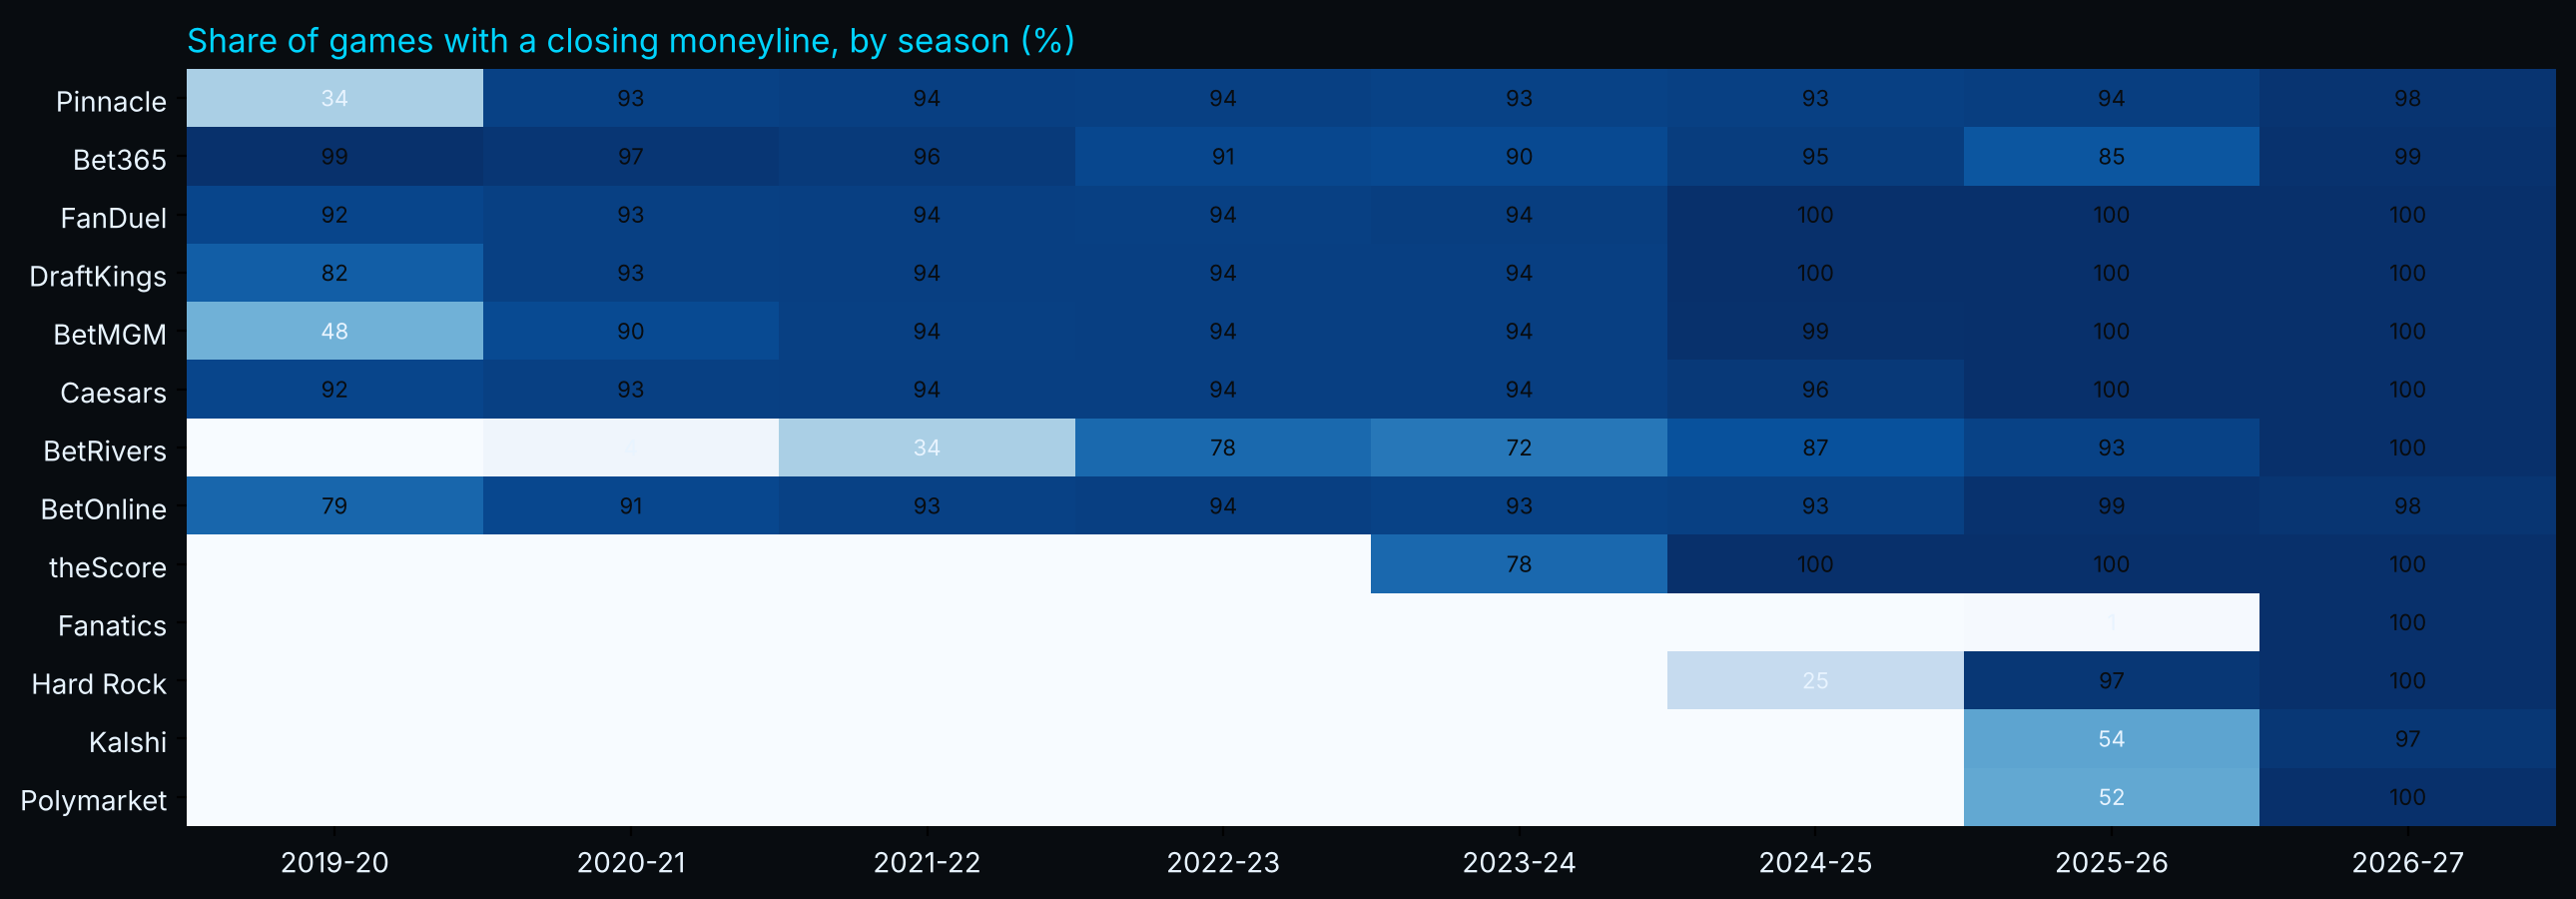

In [10]:
seasons = sorted(RAW["Season"].unique())
cov = pd.DataFrame({s: [100 * has(f"{s}_ML_Home_Close")[RAW["Season"] == se].mean() for se in seasons] for s in SOURCES},
                   index=[se.replace("/20", "-") for se in seasons])
fig, ax = plt.subplots(figsize=(13, 4.6), facecolor="#080c10")
ax.set_facecolor("#080c10")
im = ax.imshow(cov.T.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(cov.index)), cov.index, color="#e8f4ff")
ax.set_yticks(range(len(SOURCES)), [s.replace("HardRock", "Hard Rock") for s in SOURCES], color="#e8f4ff")
for i in range(len(SOURCES)):
    for j in range(len(cov.index)):
        v = cov.T.values[i, j]
        ax.text(j, i, "" if v == 0 else f"{v:.0f}", ha="center", va="center", fontsize=8, color="#080c10" if v > 55 else "#e8f4ff")
ax.set_title("Share of games with a closing moneyline, by season (%)", color="#00d4ff", loc="left")
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

## Result

In [11]:
n_ok = sum(ok for _, ok in RESULTS)
print(f"{n_ok} PASS / {len(RESULTS) - n_ok} FAIL out of {len(RESULTS)} checks")
assert n_ok == len(RESULTS), [l for l, ok in RESULTS if not ok]

69 PASS / 0 FAIL out of 69 checks


---
🏒 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/gkqmny?utm_source=github&utm_medium=notebook&utm_campaign=nhl_us&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/nhl-opening-closing-odds-9-us-books-pinnacle-2020-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nhl_us&utm_content=whop_bottom)

Licence: single commercial user. Use the data as you wish, including the models, predictions and products you sell.
Redistribution and resale of the files, or of the raw data in another format, are not permitted.
A question, an invoice or a custom extract: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*